In [ ]:
# [1] GPU·RAM·디스크 확인
import torch, shutil, os

if not torch.cuda.is_available():
    raise SystemExit("GPU가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")

p = torch.cuda.get_device_properties(0)
print(f"GPU  : {p.name} / VRAM {p.total_memory/1024**3:.1f}GB")
print(f"RAM  : {os.sysconf('SC_PAGE_SIZE')*os.sysconf('SC_PHYS_PAGES')/1024**3:.1f}GB")
print(f"디스크 여유: {shutil.disk_usage('/content').free/1024**3:.1f}GB")

GPU  : Tesla T4 / VRAM 14.6GB
RAM  : 12.7GB
디스크 여유: 112.5GB


In [ ]:
# [2] ComfyUI 본체 + 플러그인 2개 설치
import os
%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone -q https://github.com/comfyanonymous/ComfyUI.git
%cd /content/ComfyUI
!pip install -q -r requirements.txt

%cd /content/ComfyUI/custom_nodes
if not os.path.isdir("ComfyUI-GGUF"):
    !git clone -q https://github.com/city96/ComfyUI-GGUF.git          # GGUF 로더
if not os.path.isdir("comfyui_controlnet_aux"):
    !git clone -q https://github.com/Fannovel16/comfyui_controlnet_aux.git  # DWPose 포함
!pip install -q gguf
!pip install -q -r comfyui_controlnet_aux/requirements.txt
%cd /content/ComfyUI
print("\n완료: ComfyUI + GGUF + controlnet_aux 설치")

/content
/content/ComfyUI
/content/ComfyUI/custom_nodes
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
albumentations 2.0.8 requires albucore==0.0.24, but you have albucore 0.3.5 which is incompatible.
/content/ComfyUI

완료: ComfyUI + GGUF + controlnet_aux 설치


In [ ]:
# [3] 설정값 + 모델 다운로드
import os
%cd /content/ComfyUI

# ---- 설정값 (여기만 고치면 됩니다) ----
TEXT_ENCODER = "gguf"   # "gguf"(2.5GB, 기본) 또는 "bf16"(8GB)
TARGET_MP    = 0.4      # 출력 크기(메가픽셀). 메모리 부족 시 0.3
REF_MP       = 0.25     # 참조 이미지 축소 크기(메가픽셀)
STEPS        = 4        # 증류 모델 권장 4스텝
CFG          = 1.0      # FLUX.2-klein 4B 증류판 권장 1.0 (교안 노트는 4.0)
SEED         = 42       # 고정 시드

UNET_FILE = "flux-2-klein-4b-Q4_K_M.gguf"
VAE_FILE  = "flux2-vae.safetensors"
TE_FILE   = "Qwen3-4B-Q4_K_M.gguf" if TEXT_ENCODER == "gguf" else "qwen_3_4b.safetensors"

FILES = {
    f"models/diffusion_models/{UNET_FILE}":
        "https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
    f"models/vae/{VAE_FILE}":
        "https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
    f"models/text_encoders/{TE_FILE}": (
        "https://huggingface.co/unsloth/Qwen3-4B-GGUF/resolve/main/Qwen3-4B-Q4_K_M.gguf"
        if TEXT_ENCODER == "gguf" else
        "https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors"),
}

for path, url in FILES.items():
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"이미 있음: {path} ({os.path.getsize(path)/1e9:.2f}GB)")
        continue
    print(f"다운로드: {path}")
    !wget -q --show-progress -O "{path}" "{url}"

!du -sh models/diffusion_models models/text_encoders models/vae

/content/ComfyUI
다운로드: models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf
models/diffusion_mo 100%[===================>]   2.42G  84.8MB/s    in 32s     
다운로드: models/vae/flux2-vae.safetensors
models/vae/flux2-va 100%[===================>] 320.64M  98.2MB/s    in 3.6s    
다운로드: models/text_encoders/Qwen3-4B-Q4_K_M.gguf
models/text_encoder 100%[===================>]   2.33G  91.5MB/s    in 30s     
2.5G	models/diffusion_models
2.4G	models/text_encoders
321M	models/vae


In [ ]:
# [4] ComfyUI 서버를 백그라운드로 실행
import subprocess, time, os
%cd /content/ComfyUI

LOWVRAM = False   # OOM 이 나면 True 로 바꾸고 이 셀부터 다시 실행

!pkill -f "main.py --listen" 2>/dev/null
time.sleep(2)
opts = "--lowvram" if LOWVRAM else ""
os.system(f"nohup python main.py --listen 127.0.0.1 --port 8188 {opts} > /content/comfyui.log 2>&1 &")

SERVER = "http://127.0.0.1:8188"
for _ in range(90):
    time.sleep(1)
    code = subprocess.run(f"curl -s -o /dev/null -w '%{{http_code}}' {SERVER}/", shell=True,
                          capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비", SERVER)
        break
else:
    print("서버가 안 뜹니다. 로그 끝부분:")
    print(open("/content/comfyui.log").read()[-1500:])

# 필요한 노드가 모두 등록됐는지 확인
import requests
need = ["UnetLoaderGGUF", "CLIPLoaderGGUF", "DWPreprocessor", "ReferenceLatent",
        "Flux2Scheduler", "EmptyFlux2LatentImage", "CFGGuider", "SamplerCustomAdvanced"]
info = requests.get(f"{SERVER}/object_info", timeout=60).json()
missing = [n for n in need if n not in info]
print("노드 확인:", "모두 있음" if not missing else f"없음 → {missing}")

/content/ComfyUI
^C
완료: ComfyUI 서버 준비 http://127.0.0.1:8188
노드 확인: 모두 있음


▶ 모델 사진을 고르세요


Saving mail-model1.png to mail-model1.png
▶ 포즈 사진을 고르세요


Saving fmail-dance.png to fmail-dance.png
모델 사진: ['mail-model1.png']
포즈 사진: ['fmail-dance.png']


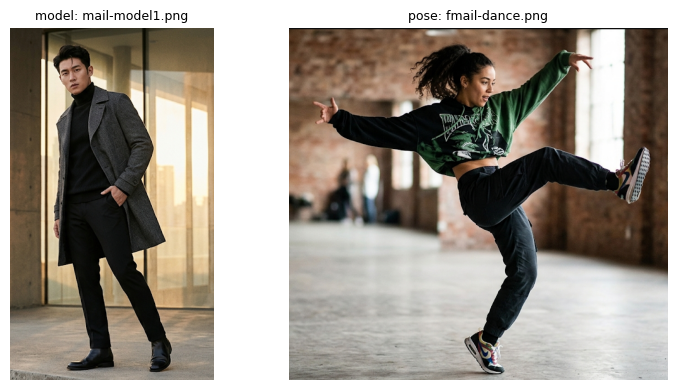

mail-model1.png (322, 557)
fmail-dance.png (600, 558)


In [ ]:
# [5] 사진 가져오기 → ComfyUI/input/ 에 복사
import os, glob, shutil
from PIL import Image
import matplotlib.pyplot as plt

REPO_URL = ""   # 기본: 빈 칸 → 업로드 창. (선택) 저장소 주소를 적으면 git clone
INPUT_DIR = "/content/ComfyUI/input"
os.makedirs(INPUT_DIR, exist_ok=True)

MODEL_IMGS, POSE_IMGS = [], []
if REPO_URL:
    !rm -rf /content/repo && git clone -q {REPO_URL} /content/repo
    for src_dir, bucket in [("/content/repo/docs/model", MODEL_IMGS), ("/content/repo/docs/pose", POSE_IMGS)]:
        for f in sorted(glob.glob(f"{src_dir}/*.png") + glob.glob(f"{src_dir}/*.jpg")):
            shutil.copy(f, INPUT_DIR); bucket.append(os.path.basename(f))
else:
    from google.colab import files
    for label, bucket in [("모델 사진", MODEL_IMGS), ("포즈 사진", POSE_IMGS)]:
        print(f"▶ {label}을 고르세요")
        for name, data in files.upload().items():
            open(f"{INPUT_DIR}/{name}", "wb").write(data); bucket.append(name)

print("모델 사진:", MODEL_IMGS)
print("포즈 사진:", POSE_IMGS)

def show(paths, titles, h=4):
    # 이미지 여러 장을 한 줄로 보여 주는 도우미
    fig, axs = plt.subplots(1, len(paths), figsize=(h*len(paths), h))
    axs = [axs] if len(paths) == 1 else axs
    for ax, pth, t in zip(axs, paths, titles):
        ax.imshow(Image.open(pth)); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

show([f"{INPUT_DIR}/{n}" for n in MODEL_IMGS + POSE_IMGS],
     [f"model: {n}" for n in MODEL_IMGS] + [f"pose: {n}" for n in POSE_IMGS])
for n in MODEL_IMGS + POSE_IMGS:
    print(n, Image.open(f"{INPUT_DIR}/{n}").size)

In [ ]:
# (스크래치 전용) 업로드가 두 번에 나뉘어 목록 바로잡기 — 짝 순서: pose_01=발레, pose_02=댄스
MODEL_IMGS = ["fmail-model1.png", "mail-model1.png"]
POSE_IMGS  = ["fmail-ballet.png", "fmail-dance.png"]
for n in MODEL_IMGS + POSE_IMGS:
    print(n, os.path.exists(f"{INPUT_DIR}/{n}"), Image.open(f"{INPUT_DIR}/{n}").size)

fmail-model1.png True (280, 561)
mail-model1.png True (322, 557)
fmail-ballet.png True (453, 531)
fmail-dance.png True (600, 558)


pose_01: fmail-ballet.png → 뼈대 추출 1.5초
pose_02: fmail-dance.png → 뼈대 추출 1.5초


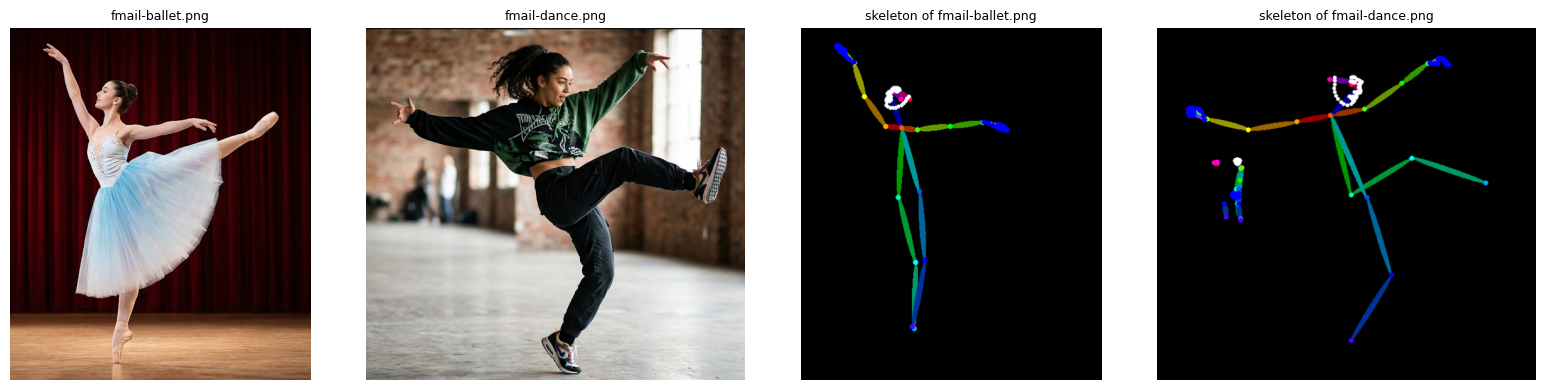

In [ ]:
# [6] 공통 도우미: 워크플로 전송 → 완료 대기 → 결과 이미지 받기
import requests, time, json, urllib.parse, uuid

def run_workflow(workflow, timeout_s=600):
    # ComfyUI 에 워크플로를 보내고, 끝나면 {노드번호: [이미지 바이트, ...]} 를 돌려준다
    r = requests.post(f"{SERVER}/prompt", json={"prompt": workflow, "client_id": str(uuid.uuid4())}, timeout=60)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:800]}")
    pid, t0 = r.json()["prompt_id"], time.time()
    while time.time() - t0 < timeout_s:
        time.sleep(1.5)
        h = requests.get(f"{SERVER}/history/{pid}", timeout=30).json()
        if pid not in h:
            continue
        entry = h[pid]
        if entry.get("status", {}).get("status_str") == "error":
            msgs = json.dumps(entry["status"].get("messages", []), ensure_ascii=False)
            raise RuntimeError("ComfyUI 실행 오류: " + msgs[-1500:])
        result = {}
        for node_id, out in entry.get("outputs", {}).items():
            for img in out.get("images", []):
                q = urllib.parse.urlencode({"filename": img["filename"], "subfolder": img.get("subfolder", ""),
                                            "type": img.get("type", "output")})
                result.setdefault(node_id, []).append(requests.get(f"{SERVER}/view?{q}", timeout=60).content)
        return result, round(time.time() - t0, 1)
    raise TimeoutError("시간 초과")

DWPOSE_INPUTS = {"detect_hand": "enable", "detect_body": "enable", "detect_face": "enable",
                 "resolution": 512, "bbox_detector": "yolox_l.onnx",
                 "pose_estimator": "dw-ll_ucoco_384_bs5.torchscript.pt",
                 "scale_stick_for_xinsr_cn": "disable"}

# 포즈 사진마다 뼈대만 뽑아서 저장
os.makedirs("/content/samples", exist_ok=True)
SKELETONS = {}
for i, pose in enumerate(POSE_IMGS, 1):
    wf = {
        "20": {"class_type": "LoadImage", "inputs": {"image": pose}},
        "21": {"class_type": "DWPreprocessor", "inputs": {"image": ["20", 0], **DWPOSE_INPUTS}},
        "24": {"class_type": "SaveImage", "inputs": {"images": ["21", 0], "filename_prefix": "skeleton"}},
    }
    out, sec = run_workflow(wf)
    skel_path = f"/content/samples/pose_{i:02d}_skeleton.png"
    open(skel_path, "wb").write(out["24"][0])
    shutil.copy(f"{INPUT_DIR}/{pose}", f"/content/samples/pose_{i:02d}.png")
    SKELETONS[pose] = skel_path
    print(f"pose_{i:02d}: {pose} → 뼈대 추출 {sec}초")

show([f"{INPUT_DIR}/{p}" for p in POSE_IMGS] + list(SKELETONS.values()),
     POSE_IMGS + [f"skeleton of {p}" for p in POSE_IMGS])

In [ ]:
# [7] 포즈 조건 생성 함수
def out_size(pose_file, target_mp=None):
    # 포즈 사진 비율을 유지하면서 넓이를 target_mp 메가픽셀로 맞춘 (가로, 세로). 16의 배수
    target_mp = target_mp or TARGET_MP
    w, h = Image.open(f"{INPUT_DIR}/{pose_file}").size
    s = (target_mp * 1e6 / (w * h)) ** 0.5
    return max(256, round(w * s / 16) * 16), max(256, round(h * s / 16) * 16)

def build_workflow(model_file, pose_file, prompt, seed=None, cfg=None, steps=None, pose_mode="skeleton"):
    W, H = out_size(pose_file)
    te_loader = ({"class_type": "CLIPLoaderGGUF", "inputs": {"clip_name": TE_FILE, "type": "flux2"}}
                 if TE_FILE.endswith(".gguf") else
                 {"class_type": "CLIPLoader", "inputs": {"clip_name": TE_FILE, "type": "flux2"}})
    pose_src = ["21", 0] if pose_mode == "skeleton" else ["20", 0]
    wf = {
        # 모델 로드
        "1":  {"class_type": "UnetLoaderGGUF", "inputs": {"unet_name": UNET_FILE}},
        "2":  te_loader,
        "3":  {"class_type": "VAELoader", "inputs": {"vae_name": VAE_FILE}},
        # 참조 1: 모델 사진 (누구를)
        "10": {"class_type": "LoadImage", "inputs": {"image": model_file}},
        "11": {"class_type": "ImageScaleToTotalPixels", "inputs": {"image": ["10", 0], "upscale_method": "lanczos",
                                                                  "megapixels": REF_MP, "resolution_steps": 1}},
        "12": {"class_type": "VAEEncode", "inputs": {"pixels": ["11", 0], "vae": ["3", 0]}},
        # 참조 2: 포즈 (어떤 자세로)
        "20": {"class_type": "LoadImage", "inputs": {"image": pose_file}},
        "22": {"class_type": "ImageScaleToTotalPixels", "inputs": {"image": pose_src, "upscale_method": "lanczos",
                                                                  "megapixels": REF_MP, "resolution_steps": 1}},
        "23": {"class_type": "VAEEncode", "inputs": {"pixels": ["22", 0], "vae": ["3", 0]}},
        # 조건: 프롬프트 + 참조 2장 (빈 조건 쪽에도 같은 참조를 붙임 — 공식 템플릿과 동일)
        "30": {"class_type": "CLIPTextEncode", "inputs": {"text": prompt, "clip": ["2", 0]}},
        "31": {"class_type": "ConditioningZeroOut", "inputs": {"conditioning": ["30", 0]}},
        "32": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["30", 0], "latent": ["12", 0]}},
        "33": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["32", 0], "latent": ["23", 0]}},
        "34": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["31", 0], "latent": ["12", 0]}},
        "35": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["34", 0], "latent": ["23", 0]}},
        # 생성
        "40": {"class_type": "CFGGuider", "inputs": {"model": ["1", 0], "positive": ["33", 0],
                                                      "negative": ["35", 0], "cfg": cfg if cfg is not None else CFG}},
        "41": {"class_type": "KSamplerSelect", "inputs": {"sampler_name": "euler"}},
        "42": {"class_type": "Flux2Scheduler", "inputs": {"steps": steps or STEPS, "width": W, "height": H}},
        "43": {"class_type": "RandomNoise", "inputs": {"noise_seed": seed if seed is not None else SEED}},
        "44": {"class_type": "EmptyFlux2LatentImage", "inputs": {"width": W, "height": H, "batch_size": 1}},
        "45": {"class_type": "SamplerCustomAdvanced", "inputs": {"noise": ["43", 0], "guider": ["40", 0],
                    "sampler": ["41", 0], "sigmas": ["42", 0], "latent_image": ["44", 0]}},
        # 출력
        "46": {"class_type": "VAEDecode", "inputs": {"samples": ["45", 0], "vae": ["3", 0]}},
        "47": {"class_type": "SaveImage", "inputs": {"images": ["46", 0], "filename_prefix": "pose_out"}},
    }
    if pose_mode == "skeleton":
        wf["21"] = {"class_type": "DWPreprocessor", "inputs": {"image": ["20", 0], **DWPOSE_INPUTS}}
    return wf, (W, H)

LOG = []   # 실험 기록 (prompts.md 로 옮길 내용)

def make_pose_image(out_id, model_file, pose_file, prompt, seed=None, cfg=None, steps=None,
                    pose_mode="skeleton", note=""):
    # 생성 → /content/samples/{out_id}.png 저장 → 기록 남기기
    wf, (W, H) = build_workflow(model_file, pose_file, prompt, seed, cfg, steps, pose_mode)
    out, sec = run_workflow(wf)
    path = f"/content/samples/{out_id}.png"
    open(path, "wb").write(out["47"][0])
    rec = {"id": out_id, "model": model_file, "pose": pose_file, "pose_mode": pose_mode, "prompt": prompt,
           "seed": seed if seed is not None else SEED, "cfg": cfg if cfg is not None else CFG,
           "steps": steps or STEPS, "size": f"{W}x{H}", "unet": UNET_FILE, "text_encoder": TE_FILE,
           "seconds": sec, "note": note}
    json.dump(rec, open(f"/content/samples/{out_id}.json", "w"), ensure_ascii=False, indent=1)
    LOG.append(rec)
    print(f"{out_id}: {W}x{H}, {sec}초")
    return path

print("함수 준비 완료: make_pose_image(out_id, model_file, pose_file, prompt, ...)")

함수 준비 완료: make_pose_image(out_id, model_file, pose_file, prompt, ...)


output_01: 592x688, 50.9초


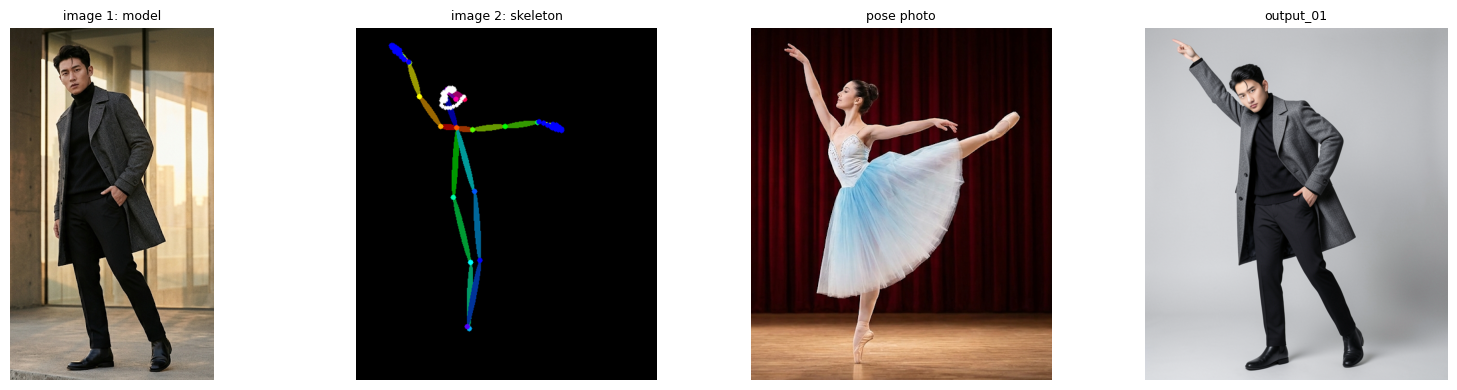

output_02: 656x608, 10.5초


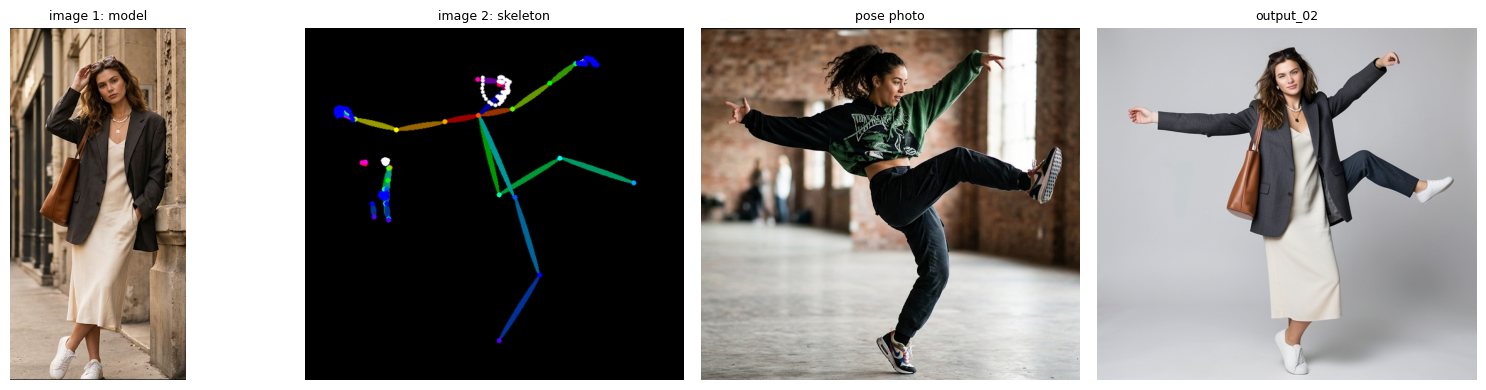

In [ ]:
# [8] 도구 동작 확인: output_01, output_02
BASE_PROMPT = ("The person from image 1 strikes exactly the same full-body pose as the stick-figure skeleton "
               "in image 2. Keep the face, hairstyle and outfit of the person in image 1. "
               "Full-body shot, the whole figure visible from head to feet, plain light grey studio background, "
               "soft even lighting. Photorealistic fashion photography.")

MALE, FEMALE = "mail-model1.png", "fmail-model1.png"
BALLET, DANCE = "fmail-ballet.png", "fmail-dance.png"
PAIRS = [("output_01", MALE, BALLET),    # pose_01 ↔ output_01
         ("output_02", FEMALE, DANCE)]   # pose_02 ↔ output_02

for out_id, m, p in PAIRS:
    assert m in MODEL_IMGS and p in POSE_IMGS, f"업로드한 파일에 {m} 또는 {p} 가 없습니다. PAIRS 를 고치세요."
    path = make_pose_image(out_id, m, p, BASE_PROMPT, note=f"도구 동작: {m} × {p}")
    show([f"{INPUT_DIR}/{m}", SKELETONS[p], f"{INPUT_DIR}/{p}", path],
         ["image 1: model", "image 2: skeleton", "pose photo", out_id])

exp1_stage: 592x688, 12.1초
exp1_costume: 592x688, 12.2초
exp1_anime: 592x688, 13.5초


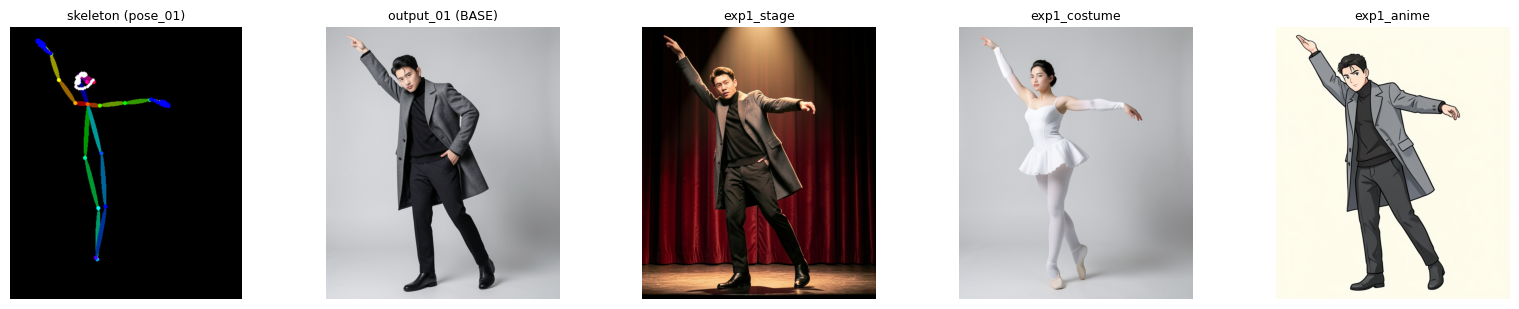

In [ ]:
# [9-1] 실험 1: 같은 포즈 · 다른 프롬프트 (남자 모델 × 발레, 기준 = output_01)
HEAD = "The person from image 1 strikes exactly the same full-body pose as the stick-figure skeleton in image 2. "
E1 = {
    "exp1_stage":   (HEAD + "Keep the face, hairstyle and outfit of the person in image 1. Full-body shot on a theatre stage, "
                     "deep red velvet curtain behind, warm spotlight from above. Photorealistic stage photography.",
                     "실험1 환경·조명: 무대"),
    "exp1_costume": (HEAD + "Keep the face and hairstyle of the person in image 1, but dress them in a fitted white ballet "
                     "costume with white tights and ballet slippers. Full-body shot, plain light grey studio background, "
                     "soft even lighting. Photorealistic fashion photography.",
                     "실험1 옷: 발레복"),
    "exp1_anime":   (HEAD + "Keep the face, hairstyle and outfit of the person in image 1. Full-body shot, plain cream background. "
                     "Clean flat 2D anime illustration with bold outlines and soft cel shading.",
                     "실험1 스타일: 일러스트"),
}
paths = [make_pose_image(k, MALE, BALLET, pr, note=nt) for k, (pr, nt) in E1.items()]
show([SKELETONS[BALLET], "/content/samples/output_01.png"] + paths,
     ["skeleton (pose_01)", "output_01 (BASE)"] + list(E1.keys()), h=3.2)

exp2_female_ballet: 592x688, 13.5초
exp2_male_dance: 656x608, 12.0초


/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 48156 (\N{HANGUL SYLLABLE BAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 47112 (\N{HANGUL SYLLABLE RE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 45828 (\N{HANGUL SYLLABLE DAEN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 50668 (\N{HANGUL SYLLA

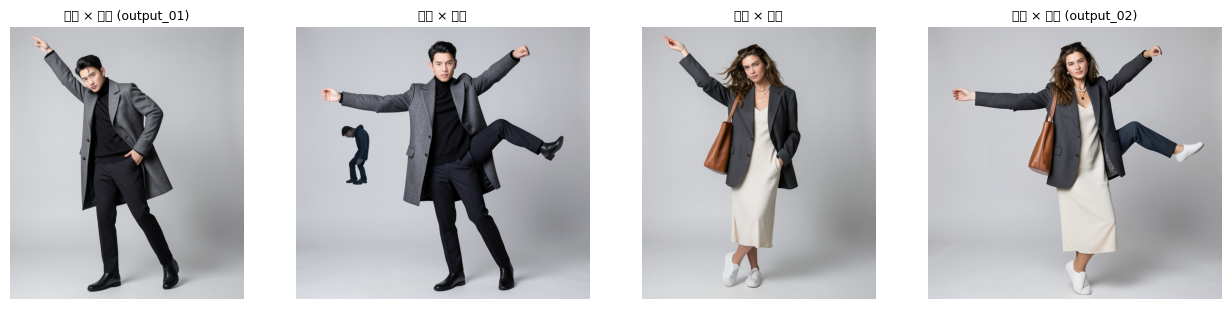

In [ ]:
# [9-2] 실험 2: 같은 프롬프트 · 다른 포즈 — 반대 짝 2장을 만들어 output_01·02 와 2×2 로 비교
e2a = make_pose_image("exp2_female_ballet", FEMALE, BALLET, BASE_PROMPT, note="실험2: 여자 모델 × 발레")
e2b = make_pose_image("exp2_male_dance",    MALE,   DANCE,  BASE_PROMPT, note="실험2: 남자 모델 × 댄스")
show(["/content/samples/output_01.png", e2b, e2a, "/content/samples/output_02.png"],
     ["남자 × 발레 (output_01)", "남자 × 댄스", "여자 × 발레", "여자 × 댄스 (output_02)"], h=3.2)

exp3_photo_ref: 592x688, 12.1초
exp4_cfg4: 592x688, 21.1초


/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 48904 (\N{HANGUL SYLLABLE BBYEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_416/815963468.py:32: UserWarning: Glyph 49324 (\N{HANGUL SY

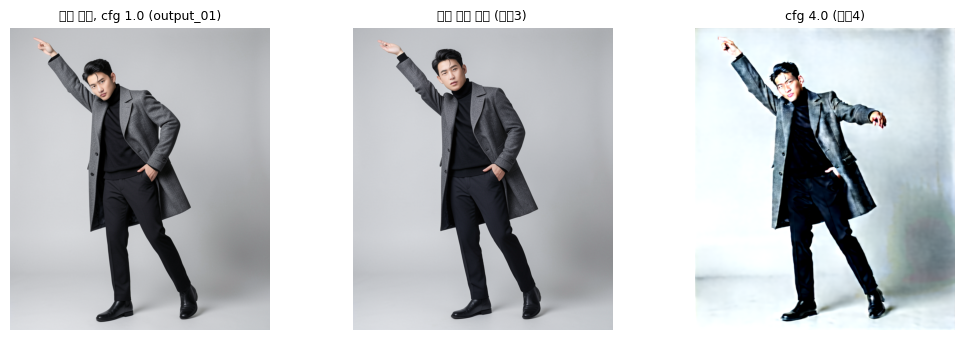

In [ ]:
# [9-3] 실험 3: 뼈대 vs 원본 포즈 사진 / [9-4] 실험 4: cfg 1.0 vs 4.0  (모두 남자 모델 × 발레)
e3 = make_pose_image("exp3_photo_ref", MALE, BALLET, BASE_PROMPT, pose_mode="photo",
                     note="실험3: 참조 2 = 원본 포즈 사진")
e4 = make_pose_image("exp4_cfg4", MALE, BALLET, BASE_PROMPT, cfg=4.0,
                     note="실험4: cfg 4.0 (교안 노트 값)")
show(["/content/samples/output_01.png", e3, e4],
     ["뼈대 참조, cfg 1.0 (output_01)", "원본 사진 참조 (실험3)", "cfg 4.0 (실험4)"], h=3.5)

In [ ]:
# [10] 기록 표 출력 + samples.zip 내려받기
rows = ["| 파일 | 모델 | 포즈 | 참조2 | cfg | 크기 | 시간(초) | 메모 |", "|---|---|---|---|---|---|---|---|"]
for r in LOG:
    rows.append(f"| {r['id']} | {r['model']} | {r['pose']} | {r['pose_mode']} | {r['cfg']} | {r['size']} | {r['seconds']} | {r['note']} |")
table = "\n".join(rows)
prompts = "\n\n".join(f"**{r['id']}** (seed {r['seed']})\n\n```\n{r['prompt']}\n```" for r in LOG)
open("/content/samples/experiment_log.md", "w").write(f"## 실험 기록\n\n{table}\n\n## 프롬프트\n\n{prompts}\n")
print(table)

!cd /content && rm -f samples.zip && zip -q -r samples.zip samples
from google.colab import files
files.download("/content/samples.zip")

| 파일 | 모델 | 포즈 | 참조2 | cfg | 크기 | 시간(초) | 메모 |
|---|---|---|---|---|---|---|---|
| output_01 | mail-model1.png | fmail-ballet.png | skeleton | 1.0 | 592x688 | 50.9 | 도구 동작: mail-model1.png × fmail-ballet.png |
| output_02 | fmail-model1.png | fmail-dance.png | skeleton | 1.0 | 656x608 | 10.5 | 도구 동작: fmail-model1.png × fmail-dance.png |
| exp1_stage | mail-model1.png | fmail-ballet.png | skeleton | 1.0 | 592x688 | 12.1 | 실험1 환경·조명: 무대 |
| exp1_costume | mail-model1.png | fmail-ballet.png | skeleton | 1.0 | 592x688 | 12.2 | 실험1 옷: 발레복 |
| exp1_anime | mail-model1.png | fmail-ballet.png | skeleton | 1.0 | 592x688 | 13.5 | 실험1 스타일: 일러스트 |
| exp2_female_ballet | fmail-model1.png | fmail-ballet.png | skeleton | 1.0 | 592x688 | 13.5 | 실험2: 여자 모델 × 발레 |
| exp2_male_dance | mail-model1.png | fmail-dance.png | skeleton | 1.0 | 656x608 | 12.0 | 실험2: 남자 모델 × 댄스 |
| exp3_photo_ref | mail-model1.png | fmail-ballet.png | photo | 1.0 | 592x688 | 12.1 | 실험3: 참조 2 = 원본 포즈 사진 |
| exp4_cfg4 | mail-model1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>